In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 1/29/2022
# version ='1.0'

# Demo: Further Experiments on Solving Geometric Programming by  Primal-Dual Interior-Point Method

In book-convex-2004, the primal-dual interior-point method was applied to the following geometric programming in convex form,
\begin{equation}
\begin{array}{rl}
\text{minimize} & f_0(x)=\log\left(\displaystyle{\sum_{k=1}^{K_0}\exp(a_{0,k}^Tx+b_{0,k})} \right) \\
\text{subject} & f_i(x)=\log\left(\displaystyle{\sum_{k=1}^{K_i}\exp(a_{i,k}^Tx+b_{i,k})} \right),i=1,2,...,m \\
\end{array}
\end{equation}
where $x\in R^{n}$.

Let
$$
\begin{array}{rcll}
\beta_{i,k} & = & \exp\left({a_{i,k}^Tx+b_{i,k}}\right) & k=1,...,K_i \\
r_i & = & \displaystyle{\sum_{k=1}^{K_i}\beta_{i,k}} & i=0,...,m  \\
\end{array}
$$
then, 
$$
\begin{array}{cc}
\begin{array}{rcl}
f_i(x) & = & \log(r_i) \\
 \\
\nabla \beta_{i,k} & = & \beta_{i,k}a_{i,k} \\
\nabla^2 \beta_{i,k} & = & \beta_{i,k}a_{i,k}a_{i,k}^T \\
\end{array} & 
\begin{array}{rcl}
\nabla r_i & = & \displaystyle{\sum_{k=1}^{K_i}\beta_{i,k}a_{i,k}} \\
\nabla^2 r_i & = & \displaystyle{\sum_{k=1}^{K_i}\beta_{i,k}a_{i,k}a_{i,k}^T} \\
\nabla f_i(x) & = & \dfrac{1}{r_i}\nabla r_i \\
\nabla^2 f_i(x) & = & \dfrac{-1}{r_i^2}(\nabla r_i)(\nabla r_i)^T + \dfrac{1}{r_i}\nabla^2 r_i\\
\end{array}
\end{array}
$$

Note that it is proved that: 0 is an eigen value of $\nabla^2 f_i(x)$ (See to appendix). This characteristics can be used to check if the python implementation is correct.

The primal-dual search direction is calculated by
$$
\begin{array}{rcl}
\left[\begin{array}{cc}
H_{0,0} & H_{0,1} \\
H_{1,0} & H_{1,1} \\
\end{array} \right]\left[\begin{array}{c}
\Delta x_{pd} \\
\Delta \lambda_{pd} \\
\end{array} \right] & = & -\left[\begin{array}{c}
r_{dual} \\
r_{cent} \\
\end{array} \right]
\end{array}
$$

where 
$$
\begin{array}{rcl}
H_{0,0} & = & \nabla^2 f_0(x) +\displaystyle{\sum_{i=1}^m\lambda_i\nabla^2f_i(x)} \\
H_{0,1} & = & Df(x)^T \\
H_{1,0} & = & -diag(\lambda)Df(x) \\
H_{1,1} & = & -diag(f(x)) \\
r_{dual} & = & \nabla f_0(x)+Df(x)^T \lambda \\
r_{cent} & = & -diag(\lambda)f(x) - (1/t)\mathbf{1} \\
\end{array}
$$
and
$$
\begin{array}{rcl}
f(x) & = & \left[\begin{array}{c}
f_1(x) \\
f_2(x) \\
\vdots \\
f_m(x) \\
\end{array} \right] \\
Df(x) & = & \left[\begin{array}{c}
\nabla f_1(x)^T \\
\nabla f_2(x)^T \\
\vdots \\
\nabla f_m(x)^T \\
\end{array} \right]
\end{array}
$$


The method to generate the model parameters, $a, b$, with optimal value one and a starting point at a duality gap of 10 has been described in the previous demo.

## Appendix

For any $y^T\in R^n$,
$$
\begin{array}{rcl}
y^T\nabla^2 f_i(x)y & = & \dfrac{-1}{r_i^2}(y^T\nabla r_i)(\nabla r_i)^Ty + \dfrac{1}{r_i}y^T(\nabla^2 r_i)y\\
& = & \dfrac{1}{r_i^2}(r_iy^T(\nabla^2r_i)y-(y^T\nabla r_i)(\nabla r_i)^Ty) \\
& = & \dfrac{1}{r_i^2} \left( \left(\displaystyle{\sum_{k=1}^{K_i}\beta_{i,k}}\right)\left( \displaystyle{\sum_{k=1}^{K_i}\beta_{i,k}[y^Ta_{i,k}][a_{i,k}^Ty]}\right) - \left(\displaystyle{\sum_{k=1}^{K_i}\beta_{i,k}[y^Ta_{i,k}]})^2\right) \right)\\
\end{array}
$$

Let $z_{i,k}=y^Ta_{i,k}\in R$, then
$$
\begin{array}{rcl}
r_i^2y^T\nabla^2 f_i(x)y & = & \left(\displaystyle{\sum_{k=1}^{K_i}\beta_{i,k}}\right) \left(\displaystyle{\sum_{k=1}^{K_i}\beta_{i,k}z_{i,k}^2}\right) - \left(\displaystyle{\sum_{k=1}^{K_i}\beta_{i,k}z_{i,k}}\right)^2
\end{array}
$$

which can reach zero when $z_{i,k}=0$ for $k=1,...,K_i$, i.e. $y \perp a_{i,k}$; or when $z_{i,k}=1$.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

$f_0(x)=\log (r_0)$

$f_i(x)=\log (r_i)$

$\nabla f_0(x)=\dfrac{\nabla r_0}{r_0}$

$\nabla f_i(x)=\dfrac{\nabla r_i}{r_i}$

$\nabla^2 f_0(x) = \dfrac{-1}{r_0^2}(\nabla r_0)(\nabla r_0)^T + \dfrac{1}{r_0}\nabla^2 r_0$

$\nabla^2 f_i(x) = \dfrac{-1}{r_i^2}(\nabla r_i)(\nabla r_i)^T + \dfrac{1}{r_i}\nabla^2 r_i$

Note that it is proved that: 0 is an eigen value of $\nabla^2 f_i(x)$ (See to appendix).
    This characteristics can be used to check if the python implementation is correct.

In [3]:
def my_f_0(r, g_r, h_r):
    """
    $f_0(x)=\log (r_0)$
    :param r:
    :param g_r:
    :param h_r:
    :return:
    """
    return np.log(r[0])


def my_f_i(i, r, g_r, h_r):
    """
    $f_i(x)=\log (r_i)$
    :param i:
    :param r:
    :param g_r:
    :param h_r:
    :return:
    """
    return np.log(r[i])


def my_f_0_feasible(r, g_r, h_r):
    return True


def my_f_i_feasible(i, r, g_r, h_r):
    return True


def my_gradient_f_0(r, g_r, h_r):
    """
    $\nabla f_0(x)=\dfrac{\nabla r_0}{r_0}$
    :param r:
    :param g_r:
    :param h_r:
    :return:
    """
    return g_r[0] / r[0]


def my_gradient_f_i(i, r, g_r, h_r):
    """
    $\nabla f_i(x)=\dfrac{\nabla r_i}{r_i}$
    :param i:
    :param r:
    :param g_r:
    :param h_r:
    :return:
    """
    return g_r[i] / r[i]


def my_hessian_f_0(r, g_r, h_r):
    """
    $\nabla^2 f_0(x) = \dfrac{-1}{r_0^2}(\nabla r_0)(\nabla r_0)^T + \dfrac{1}{r_0}\nabla^2 r_0$
    :param r:
    :param g_r:
    :param h_r:
    :return:
    """
    hessian = (-1) / (r[0] ** 2) * (g_r[0] @ g_r[0].T) + 1 / r[0] * h_r[0]

    if not np.all(np.linalg.eigvals(hessian) > 0):
        if not np.allclose(np.min(np.linalg.eigvals(hessian)), 0, atol=1e-5):
            raise RuntimeError('the hessian of f0 should be semi positive.')

    return hessian


def my_hessian_f_i(i, r, g_r, h_r):
    """
    $\nabla^2 f_i(x) = \dfrac{-1}{r_i^2}(\nabla r_i)(\nabla r_i)^T + \dfrac{1}{r_i}\nabla^2 r_i$
    :param r:
    :param g_r:
    :param h_r:
    :return:
    """
    hessian = (-1) / (r[i] ** 2) * (g_r[i] @ g_r[i].T) + 1 / r[i] * h_r[i]
    if not np.allclose(np.min(np.linalg.eigvals(hessian)), 0, atol=1e-5):
        raise RuntimeError('the hessian of fi (i={}) should be semi positive with a zero eigen value.'.format(i))
    return hessian

Refer to the lecture note for the meaning of ($r, g_r, h_r$)

For each $x$, ($r, g_r, h_r$) are calculated and cached to avoid
duplications in later calculations of gradients and hessians.

In [4]:
def my_get_r_gr_hr(x, a, b, K):
    """
    Refer to the lecture note for the meaning of ($r, g_r, h_r$)
    For each $x$, ($r, g_r, h_r$) are calculated and cached to avoid
    duplications in later calculations of gradients and hessians.
    :param x:
    :param a:
    :param b:
    :param K:
    :return:
    """
    K_max = np.max(K)
    m = len(a) - 1
    n = len(x)
    r = np.zeros((m + 1,))
    g_r = np.zeros((m + 1, n, 1))
    h_r = np.zeros((m + 1, n, n))
    beta = np.zeros((m + 1, K_max))
    for i in range(m + 1):
        for k in range(K[i]):
            beta[i][k] = np.exp(a[i][k].T @ x + b[i][k])

        r[i] = beta[i][0]
        for k in range(1, K[i]):
            r[i] += beta[i][k]

        g_r[i] = beta[i][0] * a[i][0]
        for k in range(1, K[i]):
            g_r[i] += beta[i][k] * a[i][k]

        h_r[i] = beta[i][0] * (a[i][0] @ a[i][0].T)
        for k in range(1, K[i]):
            h_r[i] += beta[i][k] * (a[i][k] @ a[i][k].T)

    return r, g_r, h_r

Given n, m, K, L
Generate model parameter, a, b, with optimal value f_asterisk

Refer to Algorithm-1 in the lecture note

In [5]:
def get_model_parameters(n, m, K, L, p_asterisk):
    """
    Given n, m, K, L
    Generate model parameter, a, b, with optimal value f_asterisk
    Refer to Algorithm-1 in the lecture note
    :param n:
    :param m:
    :param K:
    :param L:
    :param p_asterisk:
    :return:
    """
    num_zero_lambda = m - L
    lambda_ = np.random.rand(m + 1)
    if num_zero_lambda > 0:
        lambda_[1: num_zero_lambda + 1] = 0

    K_max = np.max(K)
    r = np.zeros((m + 1,))
    g_r = np.zeros((m + 1, n, 1))
    h_r = np.zeros((m + 1, n, n))
    beta = np.zeros((m + 1, K_max, 1))

    a = [[]] * (m + 1)
    b = [[]] * (m + 1)

    x_asterisk = np.random.rand(n, 1)
    for i in range(1, m + 1):
        if lambda_[i] != 0:
            r[i] = 1
        else:
            r[i] = np.random.sample()

        eta_i_tmp = np.random.rand(K[i], 1)
        sum_tmp = np.sum(eta_i_tmp)
        beta[i] = r[i] * eta_i_tmp / sum_tmp
        if not np.allclose(np.sum(beta[i]), r[i]):
            raise RuntimeError('sum of beta_i,k should be r[i]')

        a[i] = [[]] * K[i]
        b[i] = [[]] * K[i]

        for k in range(K[i]):
            a[i][k] = np.random.rand(n, 1)
            b[i][k] = np.log(beta[i][k]) - (a[i][k].T @ x_asterisk).item()
            g_r[i] += beta[i][k] * a[i][k]

        if not np.allclose(np.sum([np.exp(a[i][k].T @ x_asterisk + b[i][k]) for k in range(K[i])]), r[i]):
            raise RuntimeError('sum of exp(a[i][k]x_p + b[i][k]) should be r[i].')

    theta = np.zeros((n, 1))
    for i in range(1, m + 1):
        theta = theta - lambda_[i] / r[i] * g_r[i]

    r[0] = np.exp(p_asterisk)
    eta_tmp = np.random.rand(K[0], 1)
    sum_tmp = np.sum(eta_tmp)
    eta = eta_tmp / sum_tmp
    beta[0] = r[0] * eta

    a[0] = [[]] * K[0]
    b[0] = [[]] * K[0]
    a[0][0] = theta / eta[0]
    for k in range(1, K[0]):
        a[0][k] = np.random.rand(n, 1)
        b[0][k] = np.log(beta[0][k]) - (a[0][k].T @ x_asterisk).item()
        a[0][0] -= (eta[k] * a[0][k]) / eta[0]

    b[0][0] = np.log(beta[0][0]) - (a[0][0].T @ x_asterisk).item()

    g_r[0] = np.zeros((n, 1))
    for k in range(K[0]):
        g_r[0] += beta[0][k] * a[0][k]

    for i in range(m + 1):
        h_r[i] = np.zeros((n, n))
        for k in range(K[i]):
            h_r[i] += beta[i][k] * (a[i][k] @ a[i][k].T)

    if not np.allclose(np.log(np.sum([np.exp(a[0][k].T @ x_asterisk + b[0][k]) for k in range(K[0])])), p_asterisk):
        raise RuntimeError('The optimal value should be p^asterisk={}'.format(p_asterisk))

    for i in range(m + 1):
        sum_tmp = np.zeros((n, 1))
        for k in range(K[i]):
            sum_tmp += beta[i][k] * a[i][k]
        if not np.allclose(sum_tmp, g_r[i]):
            raise RuntimeError(r'Something wrong in calculation of $\nabla$ gamma')

        if i != 0:
            if not np.allclose(lambda_[i] * np.log(r[i]), 0):
                raise RuntimeError(r'the optimal condition $\lamba_i\log(r_i)$=0 is not satisfied.')

    grad = 1 / r[0] * g_r[0]
    for i in range(1, m + 1):
        grad += lambda_[i] / r[i] * g_r[i]

    if not np.allclose(grad, np.zeros((n, 1))):
        raise RuntimeError(r'the $\dfrac{\nabla r_0}{r_0} + \displaystyle{\sum_{i=1}^m\lambda_i \dfrac{\nabla r_i}{r_i}} = 0$ optimal condition 1 is not satisfied.')

    return a, b, beta, r, g_r, h_r, x_asterisk

x=0 is always a string feasible point

In [6]:
def get_feasible_start_at_zeros(xp):
    """
    x=0 is always a string feasible point
    :param xp:
    :return:
    """
    return np.zeros(xp.shape)

Given x_asterisk, f_asterisk, to find a start point with a duality gap equal to delta

Refer to Algorithm-1 in the lecture note

In [7]:
def get_feasible_start_with_duality_gap(a, b, K, x_asterisk, f_asterisk, delta):
    """
    Given x_asterisk, f_asterisk, to find a start point with a duality gap equal to delta
    Refer to Algorithm-1 in the lecture note
    :param a:
    :param b:
    :param K:
    :param x_asterisk:
    :param f_asterisk:
    :param delta:
    :return:
    """
    zeros = get_feasible_start_at_zeros(x_asterisk)
    r_zeros, gr_zeros, hr_zeros = my_get_r_gr_hr(zeros, a, b, K)
    f = my_f_0(r_zeros, gr_zeros, hr_zeros)
    x_low = x_asterisk
    x_high = zeros
    x = -x_asterisk
    while f < (f_asterisk + delta):
        x_low = x_high
        x = 2 * x
        x_high = x
        r, gr, hr = my_get_r_gr_hr(x, a, b, K)
        f = my_f_0(r, gr, hr)

    x_mid = (x_low + x_high) / 2
    r, gr, hr = my_get_r_gr_hr(x_mid, a, b, K)
    f_mid = my_f_0(r, gr, hr)
    while not np.allclose(f_mid, (f_asterisk + delta), atol=1e-3):
        if f_mid > f_asterisk + delta:
            x_high = x_mid
        else:
            x_low = x_mid

        x_mid = (x_low + x_high) / 2
        r, gr, hr = my_get_r_gr_hr(x_mid, a, b, K)
        f_mid = my_f_0(r, gr, hr)
        #print('fmid={}'.format(f_mid))
    return x_mid

solve the primal-dual search direction by direct matrix inversion

In [8]:
def my_primal_dual_search_direction(x, lambda_, t, a, b, K):
    """
    solve the primal-dual search direction by direct matrix inversion
    :param x:
    :param lambda_:
    :param t:
    :param a:
    :param b:
    :param K:
    :return:
    """
    m = len(a) - 1
    n = len(x)

    r, g_r, h_r = my_get_r_gr_hr(x, a, b, K)
    H_00 = my_hessian_f_0(r, g_r, h_r)
    for i in range(m):
        H_00 += lambda_[i] * my_hessian_f_i(i+1, r, g_r, h_r)

    Df = np.zeros((m, n))
    for i in range(m):
        Df[i] = my_gradient_f_i(i+1, r, g_r, h_r).T
    H_01 = Df.T

    H_10 = -np.diag(np.squeeze(lambda_)) @ Df

    fx = np.zeros((m, 1))
    for i in range(m):
        fx[i] = my_f_i(i+1, r, g_r, h_r)

    H_11 = -np.diag(np.squeeze(fx))

    H = np.block([[H_00, H_01], [H_10, H_11]])

    r_dual = my_gradient_f_0(r, g_r, h_r) + Df.T @ lambda_
    r_cent = -np.diag(np.squeeze(lambda_)) @ fx - 1 / t * np.zeros((m, 1))

    r = np.block([[r_dual], [r_cent]])

    cond = np.linalg.cond(H)
    if cond < 1e30:
        delta_y_pd = np.linalg.inv(H) @ (-r)
        delta_x_pd = delta_y_pd[0:n]
        delta_lambda_pd = delta_y_pd[n:]
        return delta_x_pd, delta_lambda_pd
    else:
        raise RuntimeError('H is not invertible.')

the standard backtracking line search method

Refer to section 11.7.3 in the textbook

In [9]:
def backtracking_line_search(x, lambda_, delta_x_pd, delta_lambda_pd, alpha, beta, t, args):
    """
    the standard backtracking line search method
    Refer to section 11.7.3 in the textbook
    :param x:
    :param lambda_:
    :param delta_x_pd:
    :param delta_lambda_pd:
    :param alpha:
    :param beta:
    :param t:
    :param args:
    :return:
    """
    a, b, K = args
    m = len(a) - 1
    n = len(x)

    tmp = [-lambda_[i][0] / delta_lambda_pd[i][0] if delta_lambda_pd[i][0] < 0 else 1 for i in range(m)]
    s_max = min(1, np.min(tmp))
    s = 0.99 * s_max
    while True:
        x_next = x + s * delta_x_pd
        r_next, g_r_next, h_r_next = my_get_r_gr_hr(x_next, a, b, K)

        feasible = True
        for i in range(m):
            if my_f_i(i+1, r_next, g_r_next, h_r_next) >= 0:
                feasible = False
                break

        if feasible:
            break
        else:
            s = beta * s

    r, g_r, h_r = my_get_r_gr_hr(x, a, b, K)
    Df = np.zeros((m, n))
    for i in range(m):
        Df[i] = my_gradient_f_i(i+1, r, g_r, h_r).T

    fx = np.zeros((m, 1))
    for i in range(m):
        fx[i] = my_f_i(i+1, r, g_r, h_r)

    r_dual = my_gradient_f_0(r, g_r, h_r) + Df.T @ lambda_
    r_cent = -np.diag(np.squeeze(lambda_)) @ fx - 1 / t * np.zeros((m, 1))
    r_current = np.block([[r_dual], [r_cent]])
    r_current_norm = np.linalg.norm(r_current)

    while True:
        x_next = x + s * delta_x_pd
        lambda_next = lambda_ + s * delta_lambda_pd

        r_next, g_r_next, h_r_next = my_get_r_gr_hr(x_next, a, b, K)
        Df_next = np.zeros((m, n))
        for i in range(m):
            Df_next[i] = my_gradient_f_i(i + 1, r_next, g_r_next, h_r_next).T

        fx_next = np.zeros((m, 1))
        for i in range(m):
            fx_next[i] = my_f_i(i + 1, r_next, g_r_next, h_r_next)

        r_dual_next = my_gradient_f_0(r_next, g_r_next, h_r_next) + Df_next.T @ lambda_next
        r_cent_next = -np.diag(np.squeeze(lambda_next)) @ fx_next - 1 / t * np.zeros((m, 1))
        r_next = np.block([[r_dual_next], [r_cent_next]])
        r_next_norm = np.linalg.norm(r_next)

        if r_next_norm <= (1 - alpha * s) * r_current_norm:
            break
        else:
            s = beta * s

    return s

 plot the progress of the convergence of $\hat{\eta}$ and $r_{feas}$

In [10]:
def plot_convergence_speed(m, n, seed, mu, num_zero_lambda, max_iteration=100):
    """
    plot the progress of the convergence of $\hat{\eta}$ and $r_{feas}$
    :param m:
    :param n:
    :param seed:
    :param mu:
    :param num_zero_lambda:
    :param max_iteration:
    :return:
    """
    plt.figure(figsize=(12, 8))
    ax1 = plt.subplot(4, 1, 1)
    ax2 = plt.subplot(4, 1, 2)
    ax3 = plt.subplot(4, 1, 3)
    ax4 = plt.subplot(4, 1, 4)

    np.random.seed(seed)
    K = [n] * (m + 1)
    p_asterisk = 0

    for z_i, zero_num in enumerate(num_zero_lambda):
        print('Info: running simulation when number of zeros in lambda is {}'.format(zero_num))
        a, b, beta, r, g_r, h_r, x_asterisk = get_model_parameters(n=n, m=m, K=K, L=m-zero_num, p_asterisk=p_asterisk)

        alpha = 0.01
        beta = 0.5
        epsilon = 1e-4
        epsilon_feas = 1e-4

        duality_gap = 10
        x0 = get_feasible_start_with_duality_gap(a, b, K, x_asterisk, p_asterisk, duality_gap)

        # initialization of $\lambda_0 \succ 0, f_i(x)<0, \mu>1$
        r_init, g_r_init, h_r_init = my_get_r_gr_hr(x0, a, b, K)
        Df_init = np.zeros((m, n))
        for i in range(m):
            Df_init[i] = my_gradient_f_i(i+1, r_init, g_r_init, h_r_init).T

        fx_init = np.zeros((m, 1))
        for i in range(m):
            fx_init[i] = my_f_i(i+1, r_init, g_r_init, h_r_init)

        lambda_0 = -1 / (fx_init)
        eta_0 = -(lambda_0.T @ (fx_init)).item()

        # log the statistics

        eta_s = [eta_0]
        r_pri = 0
        r_dual = my_gradient_f_0(r_init, g_r_init, h_r_init) + Df_init.T @ lambda_0
        r_dual_norm = np.linalg.norm(r_dual)
        r_feas = [np.sqrt(r_pri ** 2 + r_dual_norm ** 2)]
        f0_es = [my_f_0(r_init, g_r_init, h_r_init)]
        steps = []

        eta = eta_0
        x = x0
        lambda_ = lambda_0

        args = (a, b, K)
        iteration = 0
        success = False
        while True:
            t = mu * m / eta
            delta_x_pd, delta_lambda_pd = my_primal_dual_search_direction(x, lambda_, t, a, b, K)
            s = backtracking_line_search(x, lambda_, delta_x_pd, delta_lambda_pd, alpha, beta, t, args)
            x = x + s * delta_x_pd
            lambda_ = lambda_ + s * delta_lambda_pd

            # logging the statistics
            steps.append(s)
            r, g_r, h_r = my_get_r_gr_hr(x, a, b, K)
            Df = np.zeros((m, n))
            for i in range(m):
                Df[i] = my_gradient_f_i(i + 1, r, g_r, h_r).T
            fx = np.zeros((m, 1))
            for i in range(m):
                fx[i] = my_f_i(i + 1, r, g_r, h_r)
            eta = -(lambda_.T @ (fx)).item()
            eta_s.append(eta)
            r_dual = my_gradient_f_0(r, g_r, h_r) + Df.T @ lambda_
            r_dual_norm = np.linalg.norm(r_dual)
            r_feas.append(np.sqrt(r_pri ** 2 + r_dual_norm ** 2))
            f0_es.append(my_f_0(r, g_r, h_r))

            # print('Info: iteration={}, |r_dual|={}, eta={}, s={}'.format(iteration, r_dual_norm, eta, s))
            iteration += 1
            if r_dual_norm < epsilon_feas and eta < epsilon:
                success = True
                break
            if iteration > max_iteration:
                break

        if success:
            r, g_r, h_r = my_get_r_gr_hr(x, a, b, K)
            print('Info: final fp={}'.format(my_f_0(r, g_r, h_r)))

        ax1.semilogy(eta_s, marker='o', linestyle='solid', fillstyle='none', label=r'$|I[Ax-b=0]|_1$={}'.format(m-zero_num))
        ax1.xaxis.set_major_locator(MultipleLocator(5))
        ax1.set_ylabel(r'$\eta$')
        ax1.legend()

        ax2.semilogy(r_feas, marker='o', linestyle='solid', fillstyle='none', label=r'$|I[Ax-b=0]|_1$={}'.format(m-zero_num))
        ax2.xaxis.set_major_locator(MultipleLocator(5))
        ax2.set_ylabel(r'$\gamma_{feas}$')
        ax2.set_xlabel('iteration')
        ax2.legend()

        ax3.semilogy(f0_es, marker='o', linestyle='solid', fillstyle='none', label=r'$|I[Ax-b=0]|_1$={}'.format(m-zero_num))
        ax3.xaxis.set_major_locator(MultipleLocator(5))
        ax3.set_ylabel(r'$f_0(x)$')
        ax3.set_xlabel('iteration')
        ax3.legend()

        ax4.plot(steps, marker='o', linestyle='solid', fillstyle='none', label=r'$|I[Ax-b=0]|_1$={}'.format(m-zero_num))
        ax4.xaxis.set_major_locator(MultipleLocator(5))
        ax4.set_ylabel(r'$step length$')
        ax4.set_xlabel('iteration')
        ax4.legend()

    ax1.grid()
    ax2.grid()
    ax3.grid()
    ax4.grid()
    plt.show()

Info: running simulation when number of zeros in lambda is 0
Info: final fp=2.2923435081137903e-05
Info: running simulation when number of zeros in lambda is 2
Info: final fp=2.590047589604466e-07
Info: running simulation when number of zeros in lambda is 5
Info: final fp=5.8693997120545646e-05
Info: running simulation when number of zeros in lambda is 9
Info: final fp=1.267026380579696e-05


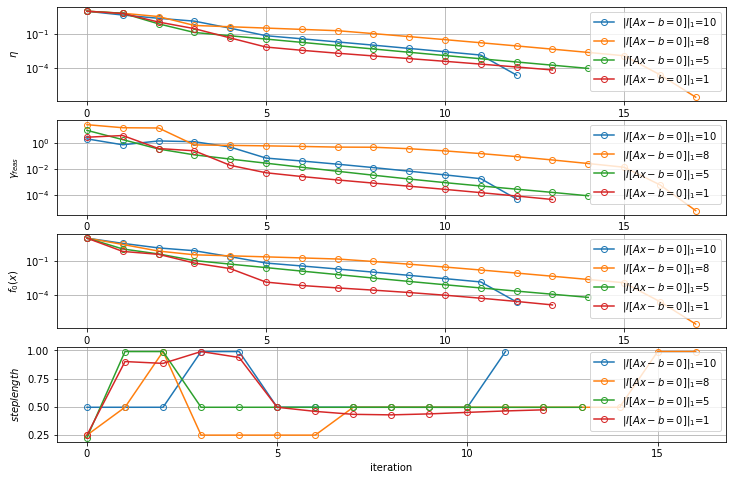

In [11]:
if __name__ == "__main__":
    plot_convergence_speed(m=10, n=5, seed=1, mu=10,
                           num_zero_lambda=[0, 2, 5, 9])